# RTP - System Identification lab exercise


Readme.txt exerpt 

```
Data-setup:

Real-time measured signals with following setup:

first  column: t/s
second column: y(t)
third  column: x(t)

columns separated by: ,
decimal separator   : .
```

In [85]:
from pathlib import Path

import matplotlib.pyplot as plt
import math 
import numpy as np
import csv

FIGURE_OUT_DIR = Path('figure_out')
FIGURE_OUT_DIR.mkdir(parents=True, exist_ok=True)


# def export_figure(filename, fig=None, folder=FIGURE_OUT_DIR, dpi=resolution):
#     figure = fig or plt.gcf()
#     output_path = folder / f'{filename}.png'
#     figure.savefig(output_path, dpi=dpi, bbox_inches='tight')
#     print(f'Exported figure to {output_path}')

resolution = 300 # dpi
fileformat = 'pdf'  # 'png' or '' + fileformat




# Task 

system files:

sys0.csv  
sys1.csv  
sys2.csv



2.2 Experiment 2 – System identification
In this experiment, the parameters of various dynamic systems have to be determined experimentally. 
For this purpose, step responses or impulse responses (see xe(t)) were recorded and saved as text files. All parameters (numerical values and units) necessary for a complete description of the system must be determined using Matlab or Python. 
Document every step thoroughly; show the graphs of the system responses with correct axis labels and add the evaluations you have programmed (tangents, intersections, etc.) and explain your approach clearly and concisely! Display

f) Determine the system behavior experimentally using the recorded step or impulse responses of
the given systems and their parameters (values and units!). Document the results, show the
essential commands and specify the differential equation and transfer function describing the
system.
g) Provide a real example for each of the determined system behaviors with a description of the
respective input and output variables!
h) Compare the given system responses with the responses of your identified system in the same
graphs and also show the deviation for each system!

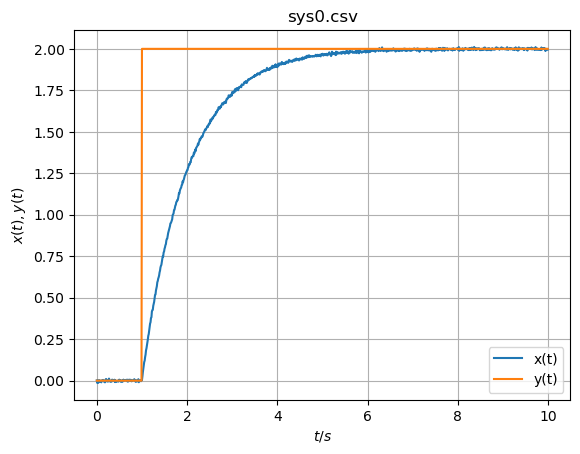

In [86]:
# Plot for sys0.csv
data0 = np.loadtxt('data/sys0.csv', delimiter=',', skiprows=1)

fig, ax = plt.subplots()
plt.plot(data0[:, 0], data0[:, 2], label='x(t)')
plt.plot(data0[:, 0], data0[:, 1], label='y(t)')
plt.title('sys0.csv')
plt.xlabel('$t/s$')
plt.ylabel('$x(t), y(t)$')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys0_raw_signals.' + fileformat, dpi=resolution)


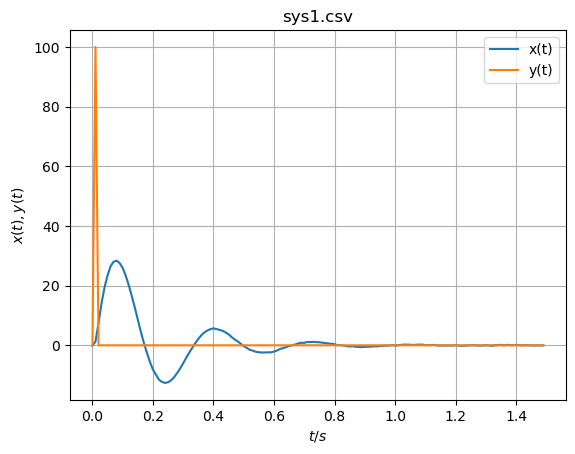

In [87]:
# Plot for sys1.csv
data1 = np.loadtxt('data/sys1.csv', delimiter=',', skiprows=1)
fig, ax = plt.subplots()
plt.plot(data1[:, 0], data1[:, 2], label='x(t)')
plt.plot(data1[:, 0], data1[:, 1], label='y(t)')
plt.title('sys1.csv')
plt.xlabel('$t/s$')
plt.ylabel('$x(t), y(t)$')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys1_raw_signals.' + fileformat, dpi=resolution)

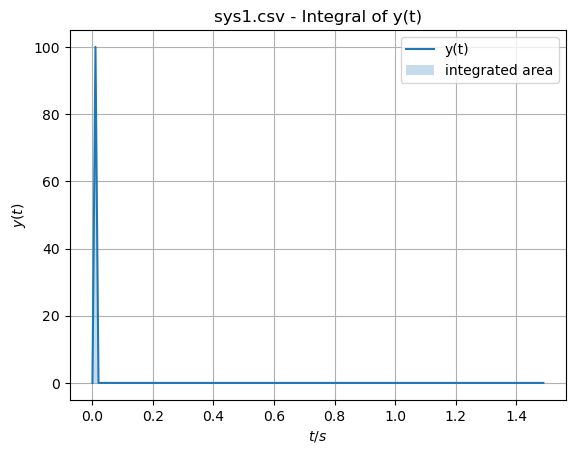

Integrated window: 0.00 s to 0.02 s
Integral of y(t): 1.000000


In [88]:
# Integral of sys1 y(t) over the pulse window
t_vals = data1[:, 0]
y_vals = data1[:, 1]

# Find the non-zero pulse and include the zero samples on both sides,
# so the triangle-shaped pulse is integrated over its full 0.02 s window.
pulse_mask = y_vals != 0

if np.any(pulse_mask):
    pulse_indices = np.flatnonzero(pulse_mask)
    start_idx = max(pulse_indices[0] - 1, 0)
    end_idx = min(pulse_indices[-1] + 1, len(y_vals) - 1)

    t_window = t_vals[start_idx:end_idx + 1]
    y_window = y_vals[start_idx:end_idx + 1]

    integral_y = np.trapezoid(y_window, t_window)

    fig, ax = plt.subplots()
    # plt.figure()
    plt.plot(t_vals, y_vals, label='y(t)')
    plt.fill_between(t_window, y_window, alpha=0.25, label='integrated area')
    plt.title('sys1.csv - Integral of y(t)')
    plt.xlabel('$t/s$')
    plt.ylabel('$y(t)$')
    plt.grid()
    plt.legend()
    plt.show()
    fig.savefig('figure_out/sys1_pulse_integral.' + fileformat, dpi=resolution)

    print(f'Integrated window: {t_window[0]:.2f} s to {t_window[-1]:.2f} s')
    print(f'Integral of y(t): {integral_y:.6f}')
else:
    print('No non-zero samples found in y(t).')

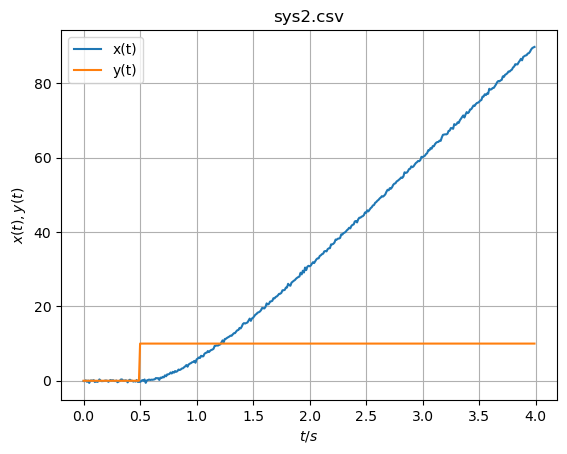

In [89]:
# Plot for sys2.csv
data2 = np.loadtxt('data/sys2.csv', delimiter=',', skiprows=1)
fig, ax = plt.subplots()
plt.plot(data2[:, 0], data2[:, 2], label='x(t)')
plt.plot(data2[:, 0], data2[:, 1], label='y(t)')
plt.title('sys2.csv')
plt.xlabel('$t/s$')
plt.ylabel('$x(t), y(t)$')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys2_raw_signals.' + fileformat, dpi=resolution)

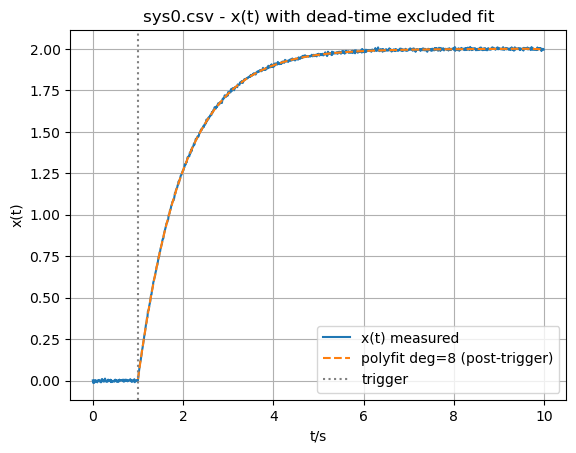

Calculated polyfit function for sys0:
            8             7            6           5          4
-1.031e-06 x + 5.312e-05 x - 0.001195 x + 0.01542 x - 0.1261 x
          3         2
 + 0.679 x - 2.396 x + 5.177 x - 3.338


In [90]:
# Polynomial fit for x(t) in sys0.csv (exclude initial dead time)
t_vals = data0[:, 0]
y_vals = data0[:, 1]
x_vals = data0[:, 2]

sys0_poly_deg = 8

# Detect trigger at y(t) step from ~0 to ~2 (crossing midpoint).
trigger_candidates = np.where((y_vals[:-1] < 1.0) & (y_vals[1:] >= 1.0))[0]
if len(trigger_candidates) > 0:
    trigger_idx = trigger_candidates[0] + 1
else:
    trigger_idx = 0

t_fit = t_vals[trigger_idx:]
x_fit_data = x_vals[trigger_idx:]
coeffs = np.polyfit(t_fit, x_fit_data, deg=sys0_poly_deg)
poly = np.poly1d(coeffs)

# Show fit only after trigger so dead time is not included visually.
x_fit = np.full_like(x_vals, np.nan, dtype=float)
x_fit[trigger_idx:] = poly(t_fit)


fig = plt.figure()
plt.plot(t_vals, x_vals, label='x(t) measured')
plt.plot(t_vals, x_fit, '--', label=f'polyfit deg={sys0_poly_deg} (post-trigger)')
plt.axvline(t_vals[trigger_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys0.csv - x(t) with dead-time excluded fit')
plt.xlabel('t/s')
plt.ylabel('x(t)')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys0_polyfit_post_trigger.' + fileformat, dpi=resolution)

print('Calculated polyfit function for sys0:')
print(poly)

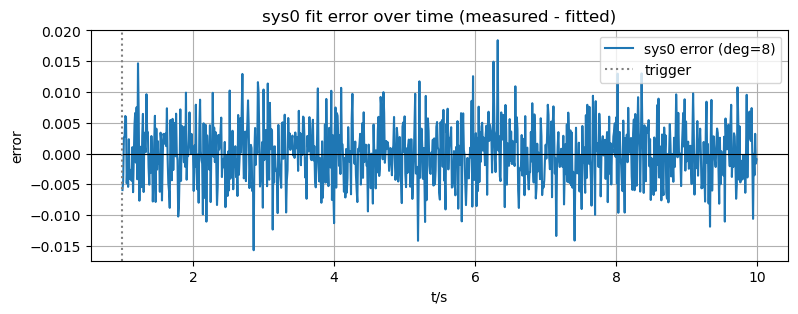

sys0 (deg=8) -> RMSE=0.004813, MAE=0.003830


In [91]:
# Fit error over time for sys0 (adapts to sys0_poly_deg)
deg0 = globals().get('sys0_poly_deg', 6)
t0 = data0[:, 0]
y0 = data0[:, 1]
x0 = data0[:, 2]

trigger0_candidates = np.where((y0[:-1] < 1.0) & (y0[1:] >= 1.0))[0]
trigger0_idx = trigger0_candidates[0] + 1 if len(trigger0_candidates) > 0 else 0

poly0 = np.poly1d(np.polyfit(t0[trigger0_idx:], x0[trigger0_idx:], deg=deg0))
x0_fit = np.full_like(x0, np.nan, dtype=float)
x0_fit[trigger0_idx:] = poly0(t0[trigger0_idx:])
err0 = x0 - x0_fit


fig = plt.figure(figsize=(9, 3))
plt.plot(t0, err0, label=f'sys0 error (deg={deg0})')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.axvline(t0[trigger0_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys0 fit error over time (measured - fitted)')
plt.xlabel('t/s')
plt.ylabel('error')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys0_polyfit_error.' + fileformat, dpi=resolution)

rmse0 = np.sqrt(np.nanmean(err0**2))
mae0 = np.nanmean(np.abs(err0))
print(f'sys0 (deg={deg0}) -> RMSE={rmse0:.6f}, MAE={mae0:.6f}')

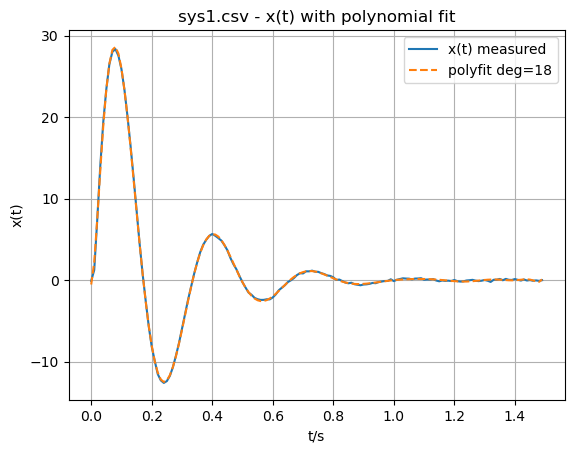

Calculated polyfit function for sys1:
           18             17             16             15
6.447e+06 x  - 8.908e+07 x  + 5.645e+08 x  - 2.173e+09 x 
              14             13             12             11
 + 5.674e+09 x  - 1.062e+10 x  + 1.471e+10 x  - 1.531e+10 x 
              10             9             8             7
 + 1.206e+10 x  - 7.198e+09 x + 3.238e+09 x - 1.091e+09 x
              6           5             4             3             2
 + 2.737e+08 x - 5.1e+07 x + 6.942e+06 x - 6.309e+05 x + 2.772e+04 x + 51.23 x - 0.5298


In [92]:
# Polynomial fit for x(t) in sys1.csv (no dead time exclusion)
t_vals = data1[:, 0]
x_vals = data1[:, 2]

sys1_poly_deg = 18

coeffs = np.polyfit(t_vals, x_vals, deg=sys1_poly_deg)
poly = np.poly1d(coeffs)
x_fit = poly(t_vals)


fig = plt.figure()
plt.plot(t_vals, x_vals, label='x(t) measured')
plt.plot(t_vals, x_fit, '--', label=f'polyfit deg={sys1_poly_deg}')
plt.title('sys1.csv - x(t) with polynomial fit')
plt.xlabel('t/s')
plt.ylabel('x(t)')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys1_polyfit.' + fileformat, dpi=resolution)

print('Calculated polyfit function for sys1:')
print(poly)

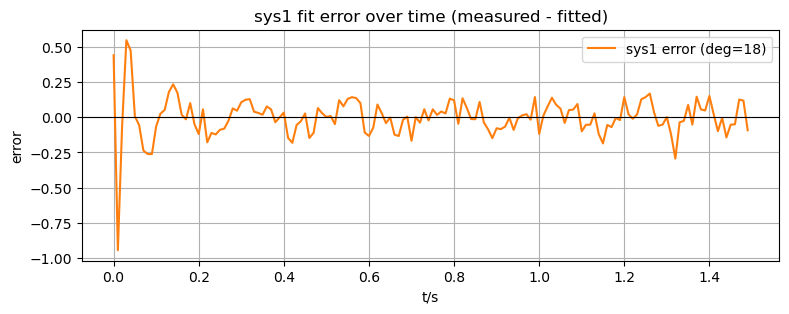

sys1 (deg=18) -> RMSE=0.141838, MAE=0.092202


In [93]:
# Fit error over time for sys1 (adapts to sys1_poly_deg)
deg1 = globals().get('sys1_poly_deg', 18)
t1 = data1[:, 0]
x1 = data1[:, 2]

poly1 = np.poly1d(np.polyfit(t1, x1, deg=deg1))
x1_fit = poly1(t1)
err1 = x1 - x1_fit

fig = plt.figure(figsize=(9, 3))
plt.plot(t1, err1, label=f'sys1 error (deg={deg1})', color='tab:orange')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.title('sys1 fit error over time (measured - fitted)')
plt.xlabel('t/s')
plt.ylabel('error')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys1_polyfit_error.' + fileformat, dpi=resolution)

rmse1 = np.sqrt(np.nanmean(err1**2))
mae1 = np.nanmean(np.abs(err1))
print(f'sys1 (deg={deg1}) -> RMSE={rmse1:.6f}, MAE={mae1:.6f}')

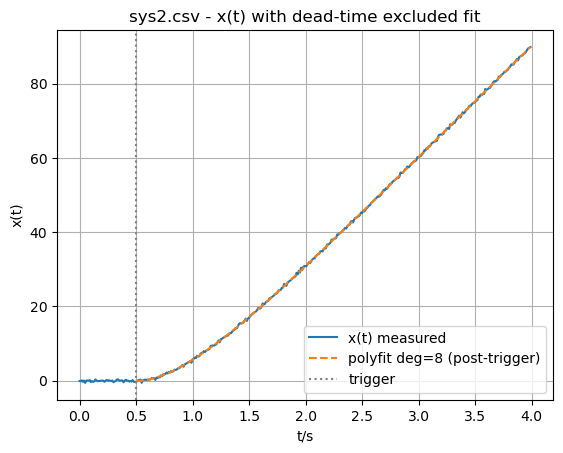

Calculated polyfit function for sys2:
         8          7         6         5         4         3         2
0.01807 x - 0.3558 x + 2.981 x - 13.98 x + 40.84 x - 78.72 x + 103.6 x - 60.83 x + 12.12


In [94]:
# Polynomial fit for x(t) in sys2.csv (exclude initial dead time)
t_vals = data2[:, 0]
y_vals = data2[:, 1]
x_vals = data2[:, 2]

sys2_poly_deg = 8

trigger_candidates = np.where((y_vals[:-1] < 1.0) & (y_vals[1:] >= 1.0))[0]
if len(trigger_candidates) > 0:
    trigger_idx = trigger_candidates[0] + 1
else:
    trigger_idx = 0

t_fit = t_vals[trigger_idx:]
x_fit_data = x_vals[trigger_idx:]
coeffs = np.polyfit(t_fit, x_fit_data, deg=sys2_poly_deg)
poly = np.poly1d(coeffs)

x_fit = np.full_like(x_vals, np.nan, dtype=float)
x_fit[trigger_idx:] = poly(t_fit)

fig = plt.figure()
plt.plot(t_vals, x_vals, label='x(t) measured')
plt.plot(t_vals, x_fit, '--', label=f'polyfit deg={sys2_poly_deg} (post-trigger)')
plt.axvline(t_vals[trigger_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys2.csv - x(t) with dead-time excluded fit')
plt.xlabel('t/s')
plt.ylabel('x(t)')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys2_polyfit_post_trigger.' + fileformat, dpi=resolution)

print('Calculated polyfit function for sys2:')
print(poly)

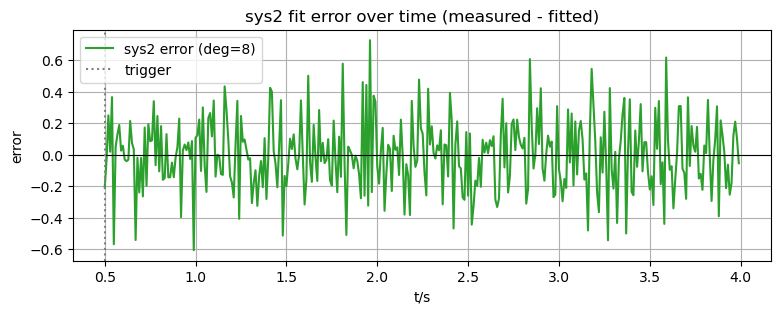

sys2 (deg=8) -> RMSE=0.226055, MAE=0.177653


In [95]:
# Fit error over time for sys2 (adapts to sys2_poly_deg)
deg2 = globals().get('sys2_poly_deg', 4)
t2 = data2[:, 0]
y2 = data2[:, 1]
x2 = data2[:, 2]

trigger2_candidates = np.where((y2[:-1] < 1.0) & (y2[1:] >= 1.0))[0]
trigger2_idx = trigger2_candidates[0] + 1 if len(trigger2_candidates) > 0 else 0

poly2 = np.poly1d(np.polyfit(t2[trigger2_idx:], x2[trigger2_idx:], deg=deg2))
x2_fit = np.full_like(x2, np.nan, dtype=float)
x2_fit[trigger2_idx:] = poly2(t2[trigger2_idx:])
err2 = x2 - x2_fit

fig = plt.figure(figsize=(9, 3))
plt.plot(t2, err2, label=f'sys2 error (deg={deg2})', color='tab:green')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.axvline(t2[trigger2_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys2 fit error over time (measured - fitted)')
plt.xlabel('t/s')
plt.ylabel('error')
plt.grid()
plt.legend()
plt.show()
fig.savefig('figure_out/sys2_polyfit_error.' + fileformat, dpi=resolution)

rmse2 = np.sqrt(np.nanmean(err2**2))
mae2 = np.nanmean(np.abs(err2))
print(f'sys2 (deg={deg2}) -> RMSE={rmse2:.6f}, MAE={mae2:.6f}')

sys0: best RMSE at degree 19 -> 0.004786
sys0: best MAE  at degree 19 -> 0.003802
sys1: best RMSE at degree 36 -> 0.114030
sys1: best MAE  at degree 36 -> 0.078684
sys2: best RMSE at degree 19 -> 0.224799
sys2: best MAE  at degree 19 -> 0.176250


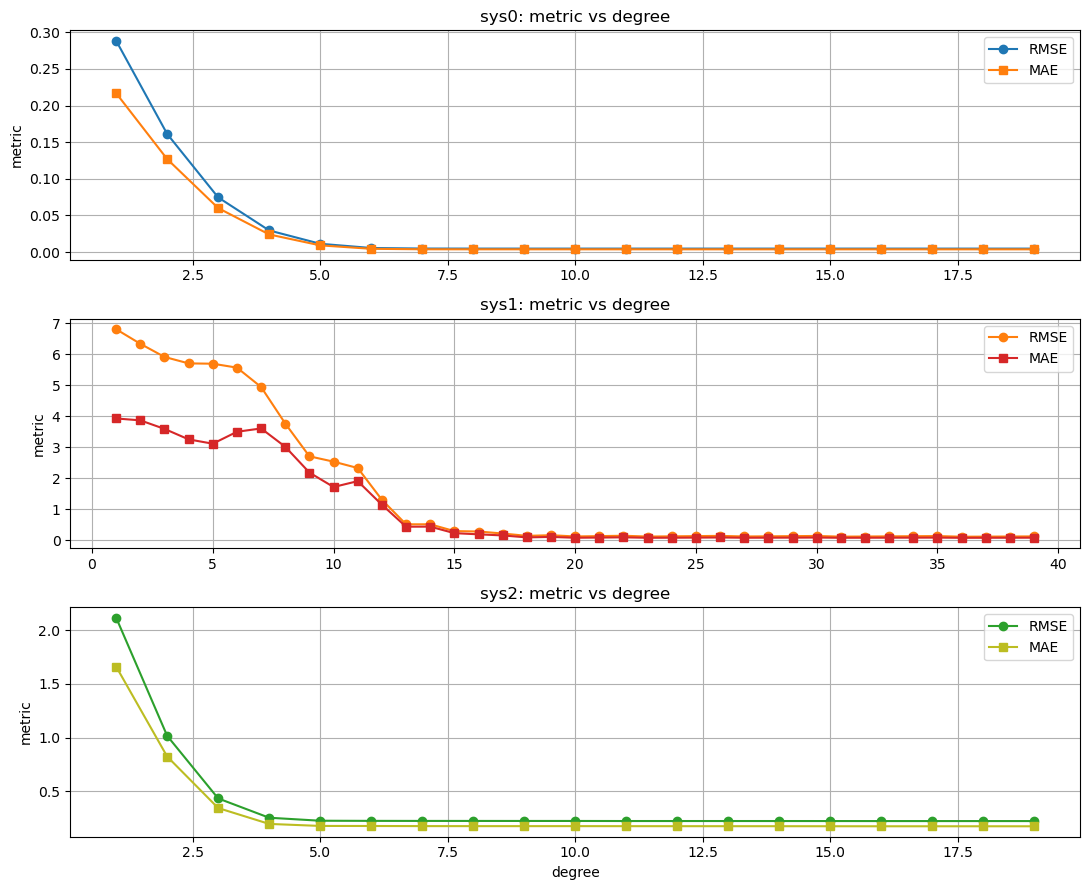

In [96]:
# Degree sweep: RMSE/MAE vs polynomial degree (objective degree selection)
import warnings

def sweep_polyfit_metrics(data, degree_range, use_deadtime, name, threshold=1.0):
    t = data[:, 0]
    y = data[:, 1]
    x = data[:, 2]

    if use_deadtime:
        trigger_candidates = np.where((y[:-1] < threshold) & (y[1:] >= threshold))[0]
        start_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
    else:
        start_idx = 0

    t_fit = t[start_idx:]
    x_fit_data = x[start_idx:]

    degrees = []
    rmses = []
    maes = []

    for deg in degree_range:
        if len(t_fit) <= deg:
            continue
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                poly = np.poly1d(np.polyfit(t_fit, x_fit_data, deg=deg))

            x_model = np.full_like(x, np.nan, dtype=float)
            x_model[start_idx:] = poly(t_fit)
            err = x - x_model

            degrees.append(deg)
            rmses.append(float(np.sqrt(np.nanmean(err**2))))
            maes.append(float(np.nanmean(np.abs(err))))
        except Exception:
            continue

    if len(degrees) == 0:
        raise ValueError(f'No valid degrees for {name}.')

    best_rmse_idx = int(np.argmin(rmses))
    best_mae_idx = int(np.argmin(maes))

    print(f'{name}: best RMSE at degree {degrees[best_rmse_idx]} -> {rmses[best_rmse_idx]:.6f}')
    print(f'{name}: best MAE  at degree {degrees[best_mae_idx]} -> {maes[best_mae_idx]:.6f}')

    return np.array(degrees), np.array(rmses), np.array(maes)

# You can change these ranges whenever you want.
deg_range0 = range(1, 20)
deg_range1 = range(1, 40)
deg_range2 = range(1, 20)

d0, r0, m0 = sweep_polyfit_metrics(data0, deg_range0, use_deadtime=True,  name='sys0')
d1, r1, m1 = sweep_polyfit_metrics(data1, deg_range1, use_deadtime=False, name='sys1')
d2, r2, m2 = sweep_polyfit_metrics(data2, deg_range2, use_deadtime=True,  name='sys2')

fig = plt.figure(figsize=(11, 9))

plt.subplot(3, 1, 1)
plt.plot(d0, r0, '-o', label='RMSE')
plt.plot(d0, m0, '-s', label='MAE')
plt.title('sys0: metric vs degree')
plt.ylabel('metric')
plt.grid()
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(d1, r1, '-o', label='RMSE', color='tab:orange')
plt.plot(d1, m1, '-s', label='MAE', color='tab:red')
plt.title('sys1: metric vs degree')
plt.ylabel('metric')
plt.grid()
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(d2, r2, '-o', label='RMSE', color='tab:green')
plt.plot(d2, m2, '-s', label='MAE', color='tab:olive')
plt.title('sys2: metric vs degree')
plt.xlabel('degree')
plt.ylabel('metric')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()
fig.savefig('figure_out/polyfit_degree_sweep.' + fileformat, dpi=resolution)

#### Section to calculate all parameters of the systems and to plot them for each system

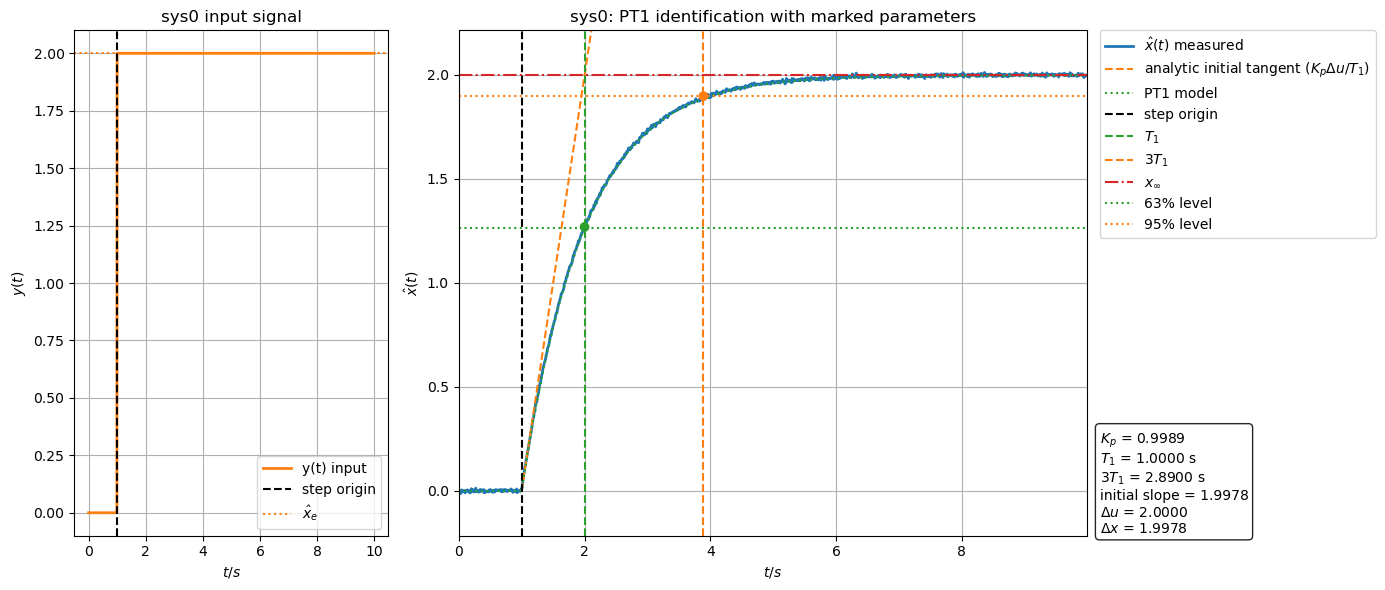

Estimated sys0 PT1 parameters:
K_p = 0.998876
T_1 = 1.000000 s
3T_1 = 2.890000 s
initial tangent slope (analytic) = 1.997752
Transfer function (PT1):
G(s) = (0.998876) / (1.000000 s + 1)


In [97]:
# sys0 PT1 identification (no dead time) with annotated plot
t = data0[:, 0]
u = data0[:, 1]  # input y(t)
x = data0[:, 2]  # output x(t)

# Trigger time from input step (0 -> 2).
trigger_candidates = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
t_step = t[trigger_idx]

# Baseline and steady-state values.
x0 = np.mean(x[:max(1, trigger_idx)])
x_inf = np.mean(x[-10:])
u0 = np.mean(u[:max(1, trigger_idx)])
u_inf = np.mean(u[trigger_idx:])
du = u_inf - u0
dx = x_inf - x0

# Static gain K_p = Delta output / Delta input.
K_p = dx / du if abs(du) > 1e-12 else np.nan

# Work on normalized response after trigger.
t_rel = t - t_step
x_norm = (x - x0) / dx if abs(dx) > 1e-12 else np.zeros_like(x)

# PT1 time markers from normalized rise (no dead time).
post = np.arange(trigger_idx, len(t))
idx_63 = post[np.where(x_norm[post] >= (1.0 - np.exp(-1.0)))[0][0]] if np.any(x_norm[post] >= (1.0 - np.exp(-1.0))) else post[-1]
idx_95 = post[np.where(x_norm[post] >= (1.0 - np.exp(-3.0)))[0][0]] if np.any(x_norm[post] >= (1.0 - np.exp(-3.0))) else post[-1]

T1 = t[idx_63] - t_step
T3 = t[idx_95] - t_step

# 63% and 95% levels in output coordinates.
x_63 = x0 + (1.0 - np.exp(-1.0)) * dx
x_95 = x0 + (1.0 - np.exp(-3.0)) * dx

# Analytic initial tangent slope: dx/dt|_{0+} = K_p * du / T_1.
slope = K_p * du / T1 if T1 > 1e-12 else 0.0

# Draw tangent only in the identification region to keep the plot scale readable.
tangent = np.full_like(t, np.nan, dtype=float)
tangent_end_time = min(t_step + T3, t[-1])
tangent_mask = (t >= t_step) & (t <= tangent_end_time)
tangent[tangent_mask] = x0 + slope * (t[tangent_mask] - t_step)

# PT1 model response for comparison (no dead time).
x_model = np.where(t_rel >= 0.0, x0 + dx * (1.0 - np.exp(-t_rel / max(T1, 1e-12))), x0)

# Two-panel plot: left input, right system response with markers.
fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2]})

# Left: input function.
ax_in.plot(t, u, color='tab:orange', label='y(t) input', linewidth=2)
ax_in.axvline(t_step, color='black', linestyle='--', label='step origin')
ax_in.axhline(u_inf, color='tab:orange', linestyle=':', label=r'$\hat{x}_e$')
ax_in.set_title('sys0 input signal')
ax_in.set_xlabel('$t/s$')
ax_in.set_ylabel('$y(t)$')
ax_in.grid()
ax_in.legend(loc='best')

# Right: output and PT1 identification markers (no dead time).
ax_out.plot(t, x, label=r'$\hat{x}(t)$ measured', linewidth=2)
ax_out.plot(t, tangent, '--', label=r'analytic initial tangent ($K_p\Delta u/T_1$)')
ax_out.plot(t, x_model, ':', label='PT1 model')

ax_out.axvline(t_step, color='black', linestyle='--', label='step origin')
ax_out.axvline(t_step + T1, color='tab:green', linestyle='--', label=r'$T_1$')
ax_out.axvline(t_step + T3, color='tab:orange', linestyle='--', label=r'$3T_1$')

# Steady-state output line.
ax_out.axhline(x_inf, color='tab:red', linestyle='-.', label=r'$x_\infty$')
ax_out.axhline(x_63, color='tab:green', linestyle=':', label='63% level')
ax_out.axhline(x_95, color='tab:orange', linestyle=':', label='95% level')
ax_out.scatter([t_step + T1, t_step + T3], [x[idx_63], x[idx_95]], color=['tab:green', 'tab:orange'], zorder=5)

# Keep readable axis range based on output signal.
y_min = np.min(x)
y_max = np.max(x)
y_pad = 0.1 * (y_max - y_min) if y_max > y_min else 1.0
ax_out.set_xlim(t[0], t[-1])
ax_out.set_ylim(y_min - y_pad, y_max + y_pad)

ax_out.set_title('sys0: PT1 identification with marked parameters')
ax_out.set_xlabel('$t/s$')
ax_out.set_ylabel(r'$\hat{x}(t)$')
ax_out.grid()
ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

# Annotation box with identified parameters, placed below the legend (outside the plot, on the right).
annot_text = (
    f'$K_p$ = {K_p:.4f}\n'
    f'$T_1$ = {T1:.4f} s\n'
    f'$3T_1$ = {T3:.4f} s\n'
    f'initial slope = {slope:.4f}\n'
    f'$\\Delta u$ = {du:.4f}\n'
    f'$\\Delta x$ = {dx:.4f}'
)
ax_out.text(
    1.02, 0.0, annot_text,
    transform=ax_out.transAxes, va='bottom', ha='left',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
)

plt.tight_layout()
plt.subplots_adjust(right=0.78)
plt.show()
fig.savefig('figure_out/sys0_pt1_identification.' + fileformat, dpi=resolution, bbox_inches='tight')

print('Estimated sys0 PT1 parameters:')
print(f'K_p = {K_p:.6f}')
print(f'T_1 = {T1:.6f} s')
print(f'3T_1 = {T3:.6f} s')
print(f'initial tangent slope (analytic) = {slope:.6f}')
print('Transfer function (PT1):')
print(f'G(s) = ({K_p:.6f}) / ({T1:.6f} s + 1)')


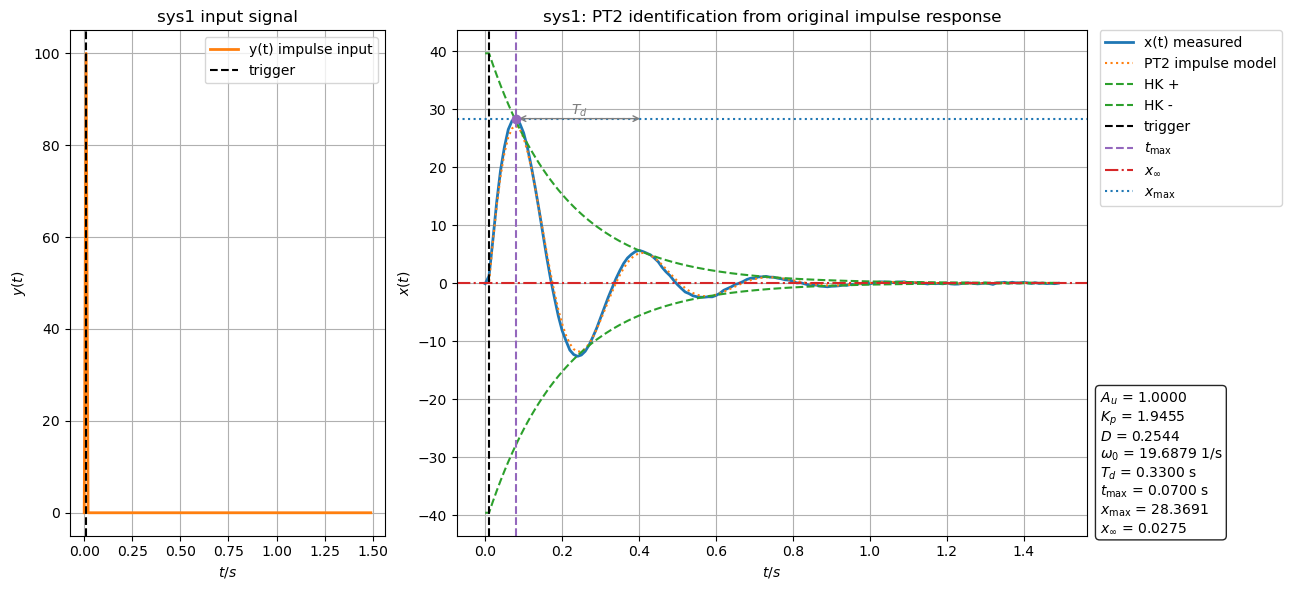

Estimated sys1 PT2 parameters from original impulse response:
A_u = 1.000000
K_p = 1.945454
D = 0.254430
omega_0 = 19.687860 1/s
T_d = 0.330000 s
t_max = 0.070000 s
x_max = 28.369144
x(inf) = 0.027507
Transfer function (PT2 form):
G(s) = (1.945454) / ((1/19.687860^2) s^2 + (2*0.254430/19.687860) s + 1)


In [98]:
# sys1 PT2 identification from original impulse response x(t)
t = data1[:, 0]
u = data1[:, 1]  # input y(t), impulse-like
x = data1[:, 2]  # measured output x(t)

# Trigger detection at first significant input rise.
u_min = float(np.min(u))
u_max = float(np.max(u))
u_mid = 0.5 * (u_min + u_max)
trigger_candidates = np.where((u[:-1] < u_mid) & (u[1:] >= u_mid))[0]
trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
t_step = t[trigger_idx]

# Input pulse area A_u = integral y(t) dt.
A_u = float(np.trapezoid(u, t))
if abs(A_u) < 1e-12:
    raise ValueError('Input pulse area is too small for PT2 identification.')

# Steady value for impulse response should be ~0 after decay.
tail_start = int(0.9 * len(t))
x_inf = float(np.mean(x[tail_start:]))
x_rel = x - x_inf

# Detect extrema after trigger using slope sign changes.
dxdt = np.gradient(x_rel, t)
max_idx = []
min_idx = []
for i in range(max(trigger_idx + 1, 1), len(t) - 1):
    if dxdt[i - 1] > 0 and dxdt[i] <= 0:
        max_idx.append(i)
    if dxdt[i - 1] < 0 and dxdt[i] >= 0:
        min_idx.append(i)
max_idx = np.array(max_idx, dtype=int)
min_idx = np.array(min_idx, dtype=int)

if len(max_idx) == 0:
    raise ValueError('No positive peak detected in impulse response.')

# First positive peak -> t_max and x_max.
first_peak_idx = int(max_idx[0])
t_max_rel = max(t[first_peak_idx] - t_step, 0.0)
x_max = float(x[first_peak_idx])
A1 = float(abs(x_rel[first_peak_idx]))

# Period T_d from first two positive peaks; fallback from positive-to-negative half period.
if len(max_idx) >= 2:
    T_d = float(t[max_idx[1]] - t[max_idx[0]])
elif len(min_idx) >= 1 and t[min_idx[0]] > t[first_peak_idx]:
    T_d = 2.0 * float(t[min_idx[0]] - t[first_peak_idx])
else:
    T_d = np.nan

# Damping D from logarithmic decrement of peak amplitudes.
if len(max_idx) >= 2:
    A2 = float(abs(x_rel[max_idx[1]]))
    if A1 > 1e-12 and A2 > 1e-12 and A1 > A2:
        delta = np.log(A1 / A2)
        D = delta / np.sqrt((2.0 * np.pi)**2 + delta**2)
    else:
        delta = np.nan
        D = np.nan
else:
    delta = np.nan
    D = np.nan

# Frequencies.
omega_d = 2.0 * np.pi / T_d if np.isfinite(T_d) and T_d > 1e-12 else np.nan
if np.isfinite(D) and 0.0 <= D < 1.0 and np.isfinite(omega_d):
    omega_0 = omega_d / np.sqrt(1.0 - D**2)
else:
    omega_0 = np.nan

# Static gain K_p from impulse-to-step relation: K_p = (1/A_u) * integral x_rel(t) dt.
K_p = float(np.trapezoid(x_rel, t) / A_u)

# Impulse-response model of underdamped PT2 for comparison.
tau = np.maximum(t - t_step, 0.0)
if np.isfinite(D) and 0.0 < D < 1.0 and np.isfinite(omega_0):
    amp = A_u * K_p * omega_0 / np.sqrt(1.0 - D**2)
    x_model = x_inf + amp * np.exp(-D * omega_0 * tau) * np.sin(omega_d * tau)
    x_env_plus = x_inf + amp * np.exp(-D * omega_0 * tau)
    x_env_minus = x_inf - amp * np.exp(-D * omega_0 * tau)
else:
    x_model = np.full_like(t, np.nan, dtype=float)
    x_env_plus = np.full_like(t, np.nan, dtype=float)
    x_env_minus = np.full_like(t, np.nan, dtype=float)

# Plot: original impulse input and original measured output with PT2 impulse fit.
fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2]})

ax_in.plot(t, u, color='tab:orange', label='y(t) impulse input', linewidth=2)
ax_in.axvline(t_step, color='black', linestyle='--', label='trigger')
ax_in.set_title('sys1 input signal')
ax_in.set_xlabel('$t/s$')
ax_in.set_ylabel('$y(t)$')
ax_in.grid()
ax_in.legend(loc='best')

ax_out.plot(t, x, label='x(t) measured', linewidth=2)
ax_out.plot(t, x_model, ':', label='PT2 impulse model')
ax_out.plot(t, x_env_plus, '--', color='tab:green', label='HK +')
ax_out.plot(t, x_env_minus, '--', color='tab:green', label='HK -')

ax_out.axvline(t_step, color='black', linestyle='--', label='trigger')
ax_out.axvline(t[first_peak_idx], color='tab:purple', linestyle='--', label=r'$t_\mathrm{max}$')
ax_out.axhline(x_inf, color='tab:red', linestyle='-.', label=r'$x_\infty$')
ax_out.axhline(x_max, color='tab:blue', linestyle=':', label=r'$x_\mathrm{max}$')
ax_out.scatter([t[first_peak_idx]], [x_max], color='tab:purple', zorder=5)

if np.isfinite(T_d):
    if len(max_idx) >= 2:
        t_p1 = t[max_idx[0]]
        t_p2 = t[max_idx[1]]
        y_arrow = max(x[max_idx[0]], x[max_idx[1]])
    else:
        t_p1 = t[first_peak_idx]
        t_p2 = t[first_peak_idx] + T_d
        y_arrow = x_max
    ax_out.annotate('', xy=(t_p1, y_arrow), xytext=(t_p2, y_arrow), arrowprops=dict(arrowstyle='<->', color='tab:gray'))
    ax_out.text((t_p1 + t_p2) / 2.0, y_arrow, r'$T_d$', color='tab:gray', ha='center', va='bottom')

ax_out.set_title('sys1: PT2 identification from original impulse response')
ax_out.set_xlabel('$t/s$')
ax_out.set_ylabel('$x(t)$')
ax_out.grid()
ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

# Annotation box with identified parameters, placed below the legend (outside the plot, on the right).
annot_text = (
    f'$A_u$ = {A_u:.4f}\n'
    f'$K_p$ = {K_p:.4f}\n'
    f'$D$ = {D:.4f}\n'
    f'$\\omega_0$ = {omega_0:.4f} 1/s\n'
    f'$T_d$ = {T_d:.4f} s\n'
    f'$t_\\mathrm{{max}}$ = {t_max_rel:.4f} s\n'
    f'$x_\\mathrm{{max}}$ = {x_max:.4f}\n'
    f'$x_\\infty$ = {x_inf:.4f}'
)
ax_out.text(
    1.02, 0.0, annot_text,
    transform=ax_out.transAxes, va='bottom', ha='left',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
)

plt.tight_layout()
plt.subplots_adjust(right=0.78)
plt.show()
fig.savefig('figure_out/sys1_pt2_identification.' + fileformat, dpi=resolution, bbox_inches='tight')

print('Estimated sys1 PT2 parameters from original impulse response:')
print(f'A_u = {A_u:.6f}')
print(f'K_p = {K_p:.6f}')
print(f'D = {D:.6f}')
print(f'omega_0 = {omega_0:.6f} 1/s')
print(f'T_d = {T_d:.6f} s')
print(f't_max = {t_max_rel:.6f} s')
print(f'x_max = {x_max:.6f}')
print(f'x(inf) = {x_inf:.6f}')
print('Transfer function (PT2 form):')
print(f'G(s) = ({K_p:.6f}) / ((1/{omega_0:.6f}^2) s^2 + (2*{D:.6f}/{omega_0:.6f}) s + 1)')


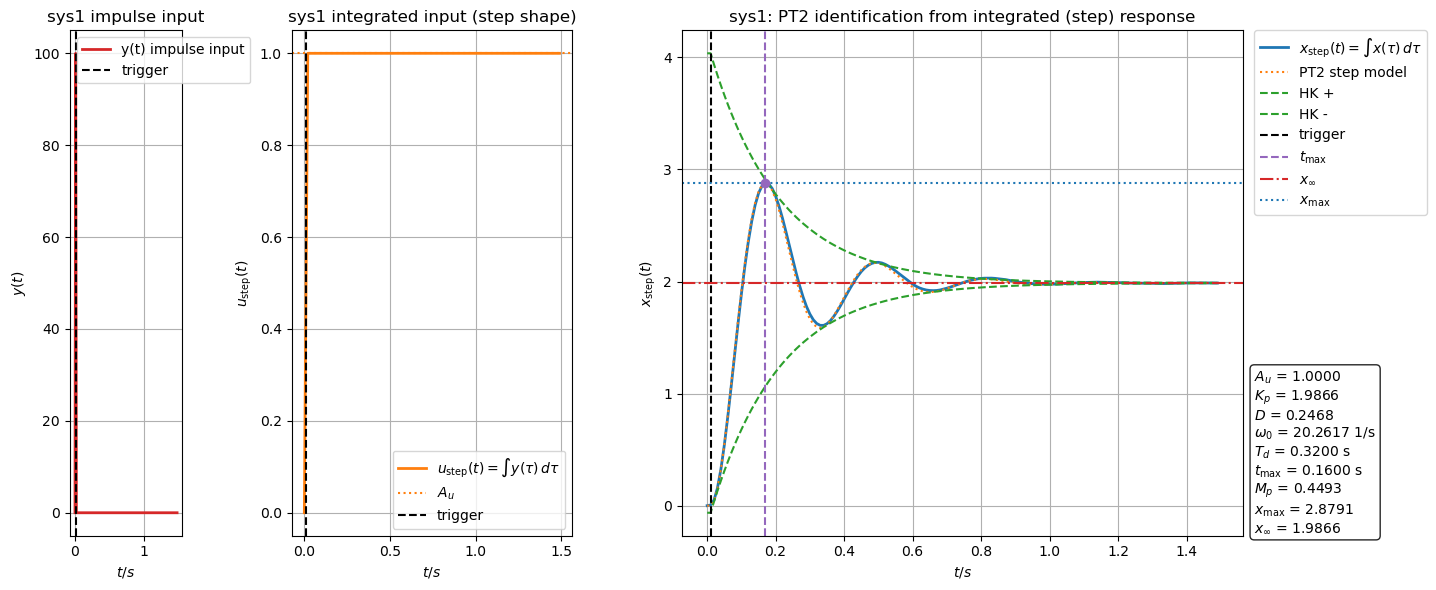

Estimated sys1 PT2 parameters from integrated step response:
A_u = 1.000000
K_p = 1.986570
D = 0.246800
omega_0 = 20.261721 1/s
T_d = 0.320000 s
t_max = 0.160000 s
M_p = 0.449286
x_step(inf) = 1.986570
Transfer function (PT2 form):
G(s) = (1.986570) / ((1/20.261721^2) s^2 + (2*0.246800/20.261721) s + 1)


In [99]:
# sys1 PT2 identification from impulse response x(t) transformed to step response via numerical integration
t = data1[:, 0]
u = data1[:, 1]  # input y(t), impulse-like
x = data1[:, 2]  # measured impulse response x(t)

# Trigger detection at first significant input rise.
u_min = float(np.min(u))
u_max = float(np.max(u))
u_mid = 0.5 * (u_min + u_max)
trigger_candidates = np.where((u[:-1] < u_mid) & (u[1:] >= u_mid))[0]
trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
t_step = t[trigger_idx]

# Cumulative trapezoidal integration: pulse -> step input, impulse response -> step response.
def cumtrapz_zero(y_, t_):
    seg = 0.5 * (y_[1:] + y_[:-1]) * np.diff(t_)
    return np.concatenate(([0.0], np.cumsum(seg)))

u_step = cumtrapz_zero(u, t)        # approaches A_u after the pulse settles
x_step = cumtrapz_zero(x, t)        # response of the linear system to u_step

A_u = float(u_step[-1])
if abs(A_u) < 1e-12:
    raise ValueError('Integrated input is too small for identification.')

# Steady-state of the integrated output (PT2 step response settles).
tail_start = int(0.9 * len(t))
x_step_inf = float(np.mean(x_step[tail_start:]))

# Static gain from integrated step response.
K_p = x_step_inf / A_u

# First peak of the step response after the trigger -> overshoot and t_max.
post = np.arange(trigger_idx, len(t))
peak_local = int(np.argmax(x_step[post]))
peak_idx = int(post[peak_local])
x_peak = float(x_step[peak_idx])
t_max_rel = max(t[peak_idx] - t_step, 0.0)

# Overshoot relative to steady value.
M_p = (x_peak - x_step_inf) / x_step_inf if abs(x_step_inf) > 1e-12 else np.nan

# Damping from logarithmic overshoot relation: M_p = exp(-pi*D/sqrt(1-D^2)).
if np.isfinite(M_p) and M_p > 0.0:
    ln_Mp = np.log(M_p)
    D = -ln_Mp / np.sqrt(np.pi**2 + ln_Mp**2)
else:
    D = np.nan

# Natural frequency from peak time: t_max = pi / (omega_0 * sqrt(1 - D^2)).
if np.isfinite(D) and 0.0 <= D < 1.0 and t_max_rel > 1e-12:
    omega_d = np.pi / t_max_rel
    omega_0 = omega_d / np.sqrt(1.0 - D**2)
    T_d = 2.0 * np.pi / omega_d
else:
    omega_d = np.nan
    omega_0 = np.nan
    T_d = np.nan

# Underdamped PT2 step response model: x(t) = K_p*A_u * (1 - e^{-D w0 t}/sqrt(1-D^2) * sin(w_d t + phi)).
tau = np.maximum(t - t_step, 0.0)
if np.isfinite(D) and 0.0 < D < 1.0 and np.isfinite(omega_0):
    phi = np.arctan2(np.sqrt(1.0 - D**2), D)
    decay = np.exp(-D * omega_0 * tau) / np.sqrt(1.0 - D**2)
    x_model = K_p * A_u * (1.0 - decay * np.sin(omega_d * tau + phi))
    x_env_plus = K_p * A_u * (1.0 + np.exp(-D * omega_0 * tau) / np.sqrt(1.0 - D**2))
    x_env_minus = K_p * A_u * (1.0 - np.exp(-D * omega_0 * tau) / np.sqrt(1.0 - D**2))
else:
    x_model = np.full_like(t, np.nan, dtype=float)
    x_env_plus = np.full_like(t, np.nan, dtype=float)
    x_env_minus = np.full_like(t, np.nan, dtype=float)

# Three-panel plot: slim impulse input, integrated step input, integrated output with PT2 fit.
fig, (ax_pulse, ax_in, ax_out) = plt.subplots(
    1, 3, figsize=(16, 6), gridspec_kw={'width_ratios': [0.4, 1, 2]}
)

ax_pulse.plot(t, u, color='tab:red', label='y(t) impulse input', linewidth=2)
ax_pulse.axvline(t_step, color='black', linestyle='--', label='trigger')
ax_pulse.set_title('sys1 impulse input')
ax_pulse.set_xlabel('$t/s$')
ax_pulse.set_ylabel('$y(t)$')
ax_pulse.grid()
ax_pulse.legend(loc='best')

ax_in.plot(t, u_step, color='tab:orange', label=r'$u_\mathrm{step}(t)=\int y(\tau)\,d\tau$', linewidth=2)
ax_in.axhline(A_u, color='tab:orange', linestyle=':', label=r'$A_u$')
ax_in.axvline(t_step, color='black', linestyle='--', label='trigger')
ax_in.set_title('sys1 integrated input (step shape)')
ax_in.set_xlabel('$t/s$')
ax_in.set_ylabel(r'$u_\mathrm{step}(t)$')
ax_in.grid()
ax_in.legend(loc='best')

ax_out.plot(t, x_step, label=r'$x_\mathrm{step}(t)=\int x(\tau)\,d\tau$', linewidth=2)
ax_out.plot(t, x_model, ':', label='PT2 step model')
ax_out.plot(t, x_env_plus, '--', color='tab:green', label='HK +')
ax_out.plot(t, x_env_minus, '--', color='tab:green', label='HK -')

ax_out.axvline(t_step, color='black', linestyle='--', label='trigger')
ax_out.axvline(t[peak_idx], color='tab:purple', linestyle='--', label=r'$t_\mathrm{max}$')
ax_out.axhline(x_step_inf, color='tab:red', linestyle='-.', label=r'$x_\infty$')
ax_out.axhline(x_peak, color='tab:blue', linestyle=':', label=r'$x_\mathrm{max}$')
ax_out.scatter([t[peak_idx]], [x_peak], color='tab:purple', zorder=5)

ax_out.set_title('sys1: PT2 identification from integrated (step) response')
ax_out.set_xlabel('$t/s$')
ax_out.set_ylabel(r'$x_\mathrm{step}(t)$')
ax_out.grid()
ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

annot_text = (
    f'$A_u$ = {A_u:.4f}\n'
    f'$K_p$ = {K_p:.4f}\n'
    f'$D$ = {D:.4f}\n'
    f'$\\omega_0$ = {omega_0:.4f} 1/s\n'
    f'$T_d$ = {T_d:.4f} s\n'
    f'$t_\\mathrm{{max}}$ = {t_max_rel:.4f} s\n'
    f'$M_p$ = {M_p:.4f}\n'
    f'$x_\\mathrm{{max}}$ = {x_peak:.4f}\n'
    f'$x_\\infty$ = {x_step_inf:.4f}'
)
ax_out.text(
    1.02, 0.0, annot_text,
    transform=ax_out.transAxes, va='bottom', ha='left',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
)

plt.tight_layout()
plt.subplots_adjust(right=0.78)
plt.show()
fig.savefig('figure_out/sys1_pt2_identification_step.' + fileformat, dpi=resolution, bbox_inches='tight')

print('Estimated sys1 PT2 parameters from integrated step response:')
print(f'A_u = {A_u:.6f}')
print(f'K_p = {K_p:.6f}')
print(f'D = {D:.6f}')
print(f'omega_0 = {omega_0:.6f} 1/s')
print(f'T_d = {T_d:.6f} s')
print(f't_max = {t_max_rel:.6f} s')
print(f'M_p = {M_p:.6f}')
print(f'x_step(inf) = {x_step_inf:.6f}')
print('Transfer function (PT2 form):')
print(f'G(s) = ({K_p:.6f}) / ((1/{omega_0:.6f}^2) s^2 + (2*{D:.6f}/{omega_0:.6f}) s + 1)')


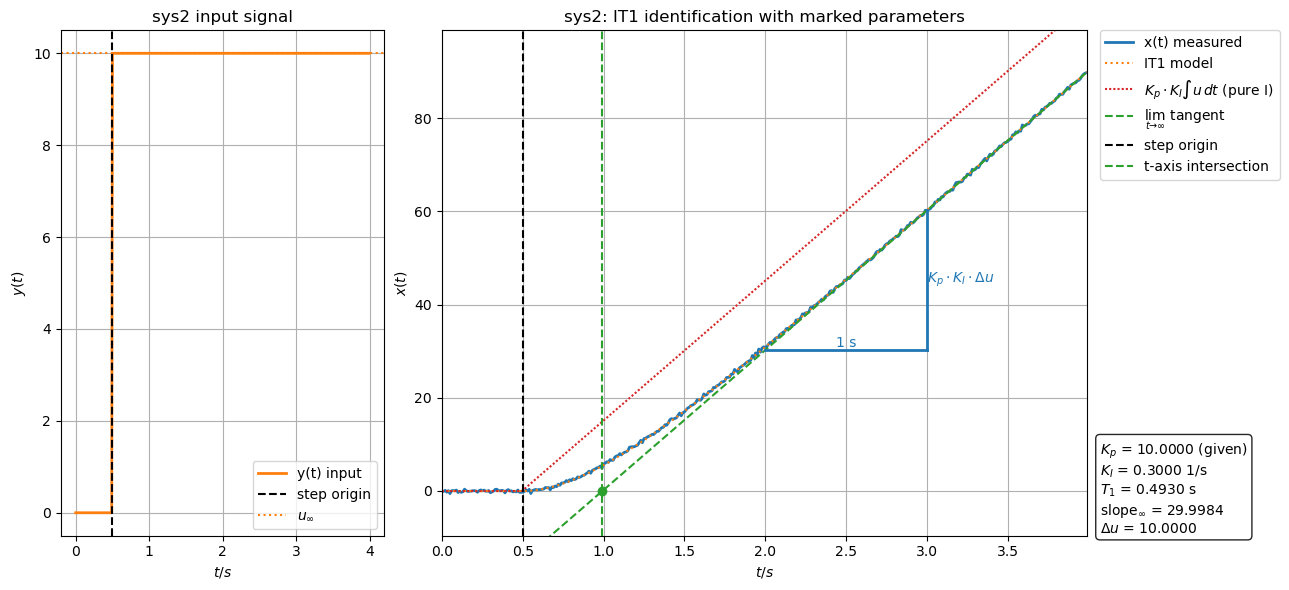

Estimated sys2 IT1 parameters (with K_p = 10 given):
K_p (given) = 10.000000
K_I = 0.299984 1/s
T_1 = 0.492994 s
Transfer function (IT1, including K_p):
G(s) = (10.000000 * 0.299984) / (s * (0.492994 s + 1))


In [100]:
# sys2 IT1 identification (no dead time) with annotated plot
t = data2[:, 0]
u = data2[:, 1]  # input y(t)
x = data2[:, 2]  # output x(t)

# Plant proportional factor known from setup (input scaling K_p = 10).
K_p_plant = 10.0

# Step detection on input (0 -> 2).
trigger_candidates = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
t_step = t[trigger_idx]

# Input step height.
u0 = np.mean(u[:max(1, trigger_idx)])
u_inf = np.mean(u[trigger_idx:])
du = u_inf - u0

# Asymptotic tangent (lim t->inf) from last part of the measured response.
tail_start = int(0.75 * len(t))
if len(t) - tail_start < 5:
    tail_start = max(trigger_idx, len(t) - 5)
slope_inf, intercept_inf = np.polyfit(t[tail_start:], x[tail_start:], 1)

# K_I from asymptotic slope: slope_inf = K_p_plant * K_I * delta_u
# (the IT1 is preceded by a proportional element with K_p = 10).
K_I = slope_inf / (du * K_p_plant) if abs(du) > 1e-12 else np.nan

# Intersection of asymptotic tangent with time axis (x = 0).
t_intersect = -intercept_inf / slope_inf if abs(slope_inf) > 1e-12 else np.nan

# T_1 from tangent intersection relative to step origin (no dead time).
T_1 = t_intersect - t_step if np.isfinite(t_intersect) else np.nan
if np.isfinite(T_1):
    T_1 = max(T_1, 1e-6)

# IT1 model response to a step (no dead time) for visual comparison.
x0 = np.mean(x[:max(1, trigger_idx)])
tau = t - t_step
tau_pos = np.maximum(tau, 0.0)
if np.isfinite(T_1):
    x_model = x0 + K_p_plant * K_I * du * (tau_pos - T_1 * (1.0 - np.exp(-tau_pos / T_1)))
else:
    x_model = x0 + K_p_plant * K_I * du * tau_pos

# Pure-I reference: K_p_plant * K_I * integral(u(t) - u0) dt, plotted as dotted line.
# Differs from the measured IT1 response by the first-order lag T_1.
u_eff = u - u0
x_int = x0 + K_p_plant * K_I * np.concatenate(([0.0], np.cumsum(0.5 * (u_eff[1:] + u_eff[:-1]) * np.diff(t))))

# Asymptotic tangent line over plotting range.
tangent_inf = slope_inf * t + intercept_inf

# Plot: left input, right output identification.
fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2]})

ax_in.plot(t, u, color='tab:orange', label='y(t) input', linewidth=2)
ax_in.axvline(t_step, color='black', linestyle='--', label='step origin')
ax_in.axhline(u_inf, color='tab:orange', linestyle=':', label=r'$u_\infty$')
ax_in.set_title('sys2 input signal')
ax_in.set_xlabel('$t/s$')
ax_in.set_ylabel('$y(t)$')
ax_in.grid()
ax_in.legend(loc='best')

ax_out.plot(t, x, label='x(t) measured', linewidth=2)
ax_out.plot(t, x_model, ':', label='IT1 model')
ax_out.plot(t, x_int, linestyle=(0, (1, 1)), color='tab:red', label=r'$K_p \cdot K_I \int u\,dt$ (pure I)')
ax_out.plot(t, tangent_inf, '--', label=r'$\lim_{t\to\infty}$ tangent')

ax_out.axvline(t_step, color='black', linestyle='--', label='step origin')
if np.isfinite(t_intersect):
    ax_out.axvline(t_intersect, color='tab:green', linestyle='--', label='t-axis intersection')
    ax_out.scatter([t_intersect], [0.0], color='tab:green', zorder=5)

# Slope triangle on the asymptotic tangent: delta t = 1 s.
triangle_shift = 1.0
triangle_base = t_step + 0.5 + triangle_shift
t_tri0 = max(triangle_base, t[0])
t_tri1 = min(t_tri0 + 1.0, t[-1])
if t_tri1 - t_tri0 < 1e-9:
    t_tri0 = max(t[-1] - 1.0, t[0])
    t_tri1 = t[-1]
x_tri0 = slope_inf * t_tri0 + intercept_inf
x_tri1 = slope_inf * t_tri1 + intercept_inf

ax_out.plot([t_tri0, t_tri1], [x_tri0, x_tri0], color='tab:blue', linewidth=2)
ax_out.plot([t_tri1, t_tri1], [x_tri0, x_tri1], color='tab:blue', linewidth=2)
ax_out.text((t_tri0 + t_tri1) / 2.0, x_tri0, '1 s', color='tab:blue', ha='center', va='bottom')
ax_out.text(t_tri1, (x_tri0 + x_tri1) / 2.0, r'$K_p \cdot K_I \cdot \Delta u$', color='tab:blue', ha='left', va='center')

# Keep readable scale from measured output.
y_min = np.min(x)
y_max = np.max(x)
y_pad = 0.1 * (y_max - y_min) if y_max > y_min else 1.0
ax_out.set_xlim(t[0], t[-1])
ax_out.set_ylim(y_min - y_pad, y_max + y_pad)

ax_out.set_title('sys2: IT1 identification with marked parameters')
ax_out.set_xlabel('$t/s$')
ax_out.set_ylabel('$x(t)$')
ax_out.grid()
ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

# Annotation box with identified parameters, placed below the legend (outside the plot, on the right).
annot_text = (
    f'$K_p$ = {K_p_plant:.4f} (given)\n'
    f'$K_I$ = {K_I:.4f} 1/s\n'
    f'$T_1$ = {T_1:.4f} s\n'
    f'slope$_\\infty$ = {slope_inf:.4f}\n'
    f'$\\Delta u$ = {du:.4f}'
)
ax_out.text(
    1.02, 0.0, annot_text,
    transform=ax_out.transAxes, va='bottom', ha='left',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
)

plt.tight_layout()
plt.subplots_adjust(right=0.78)
plt.show()
fig.savefig('figure_out/sys2_it1_identification.' + fileformat, dpi=resolution, bbox_inches='tight')

print('Estimated sys2 IT1 parameters (with K_p = 10 given):')
print(f'K_p (given) = {K_p_plant:.6f}')
print(f'K_I = {K_I:.6f} 1/s')
print(f'T_1 = {T_1:.6f} s')
print('Transfer function (IT1, including K_p):')
print(f'G(s) = ({K_p_plant:.6f} * {K_I:.6f}) / (s * ({T_1:.6f} s + 1))')


#### Calculating the system deviation from the optimal system parametric response values

#### Section to plot the Regeungstechnische and Simulink Model each system 